## Análisis de Raster de elevación

In [1]:
import pandas as pd 
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent
from rasterio.windows import from_bounds
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer
import shapely
from rasterio.mask import mask
from shapely.geometry import mapping
from shapely.geometry import box
from rasterio.transform import xy
from collections import Counter
from pathlib import Path

In [2]:
parcelas_gdf = gpd.read_file('../../DataSet/DATASET_RETO_AGRO_2026/Parcelas_Reto_AGC_CONJUNTO_70_30/Parcelas_Reto_AGC_CONJUNTO.shp')

parcelas_gdf.head()

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."


In [3]:
print(f'Shape: {parcelas_gdf.shape}')
print(f'CRS: {parcelas_gdf.crs}')
print(f'Columns: {parcelas_gdf.columns}')

Shape: (197, 7)
CRS: EPSG:4326
Columns: Index(['Cultivo', 'ID_POLIGON', 'área_ha', 'Municipio', 'Estado', 'CONJUNTO',
       'geometry'],
      dtype='str')


In [4]:
elev_path = '../../DataSet/DATASET_RETO_AGRO_2026/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Reto_AgroCebada_Topografia_INEGI_CEM4/Elevacion_INEGI_CEM4_120m.tif'

print('Elevación:')

with rasterio.open(elev_path) as src_elev:
    print(f'CSR: {src_elev.crs}')
    print(f'Dimensiones: {src_elev.width} x {src_elev.height}')
    print(f'Bandas: {src_elev.count}')
    print(f'Resolución: {src_elev.res}')
    print(f'Bounds: {src_elev.bounds}')
    print(f'No Data: {src_elev.nodata}')
    print(f'Data type: {src_elev.dtypes[0]}')

Elevación:
CSR: EPSG:6372
Dimensiones: 2900 x 3362
Bandas: 1
Resolución: (120.0, 120.0)
Bounds: BoundingBox(left=2715840.0, bottom=650400.0, right=3063840.0, top=1053840.0)
No Data: -9999.0
Data type: float32


In [5]:
parcela = parcelas_gdf[parcelas_gdf['ID_POLIGON'] == 'AGC_001'].copy()

print(parcela[["ID_POLIGON", "área_ha", "CONJUNTO"]])
print(f'CRS: {parcela.crs}')
print(f'Geometría: {parcela.geometry.iloc[0].geom_type}')

    ID_POLIGON  área_ha       CONJUNTO
196    AGC_001     7.61  ENTRENAMIENTO
CRS: EPSG:4326
Geometría: Polygon


Los datos de topografía vienen diferentes a los de precipitación y temperatura, para que se puedan utilizar juntos realizamos una reproyección, para que estén del mismo formato.


In [6]:
parcela_repro = parcela.to_crs("EPSG:6372")

print(f'Parcel original: {parcela.crs}')
print(f'Parcel reproyectada: {parcela_repro.crs}')

Parcel original: EPSG:4326
Parcel reproyectada: EPSG:6372


In [7]:
area_calculada_m2 = parcela_repro.geometry.area.iloc[0]
area_calculada_ha = area_calculada_m2 / 10_000

print("Área del dataset:", parcela["área_ha"].iloc[0], "ha")
print("Área calculada:", area_calculada_ha, "ha")

Área del dataset: 7.61 ha
Área calculada: 7.568578283383907 ha


In [8]:
#Raster de elevación

with rasterio.open(elev_path) as elev_src:
    print(f'Raster CRS: {elev_src.crs}')
    print(f'Resolución: {elev_src.res}')
    
    transform = elev_src.transform
    elevacion = elev_src.read(1)

print(f'Límites de nuestra parcela: {parcela_repro.total_bounds}')

Raster CRS: EPSG:6372
Resolución: (120.0, 120.0)
Límites de nuestra parcela: [2859490.66598076  842240.93525043 2859815.28122795  842698.08343805]


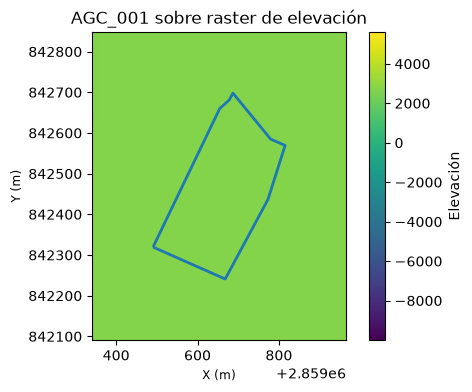

In [9]:
from rasterio.plot import plotting_extent

with rasterio.open(elev_path) as src:
    elevacion = src.read(1)
    extent = plotting_extent(elevacion, src.transform)

fig, ax = plt.subplots(figsize=(6, 4))

# Raster de elevación
im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2
)

# Límites de la parcela
xmin, ymin, xmax, ymax = parcela_repro.total_bounds

ax.set_xlim(xmin - 150, xmax + 150)
ax.set_ylim(ymin - 150, ymax + 150)

ax.set_title("AGC_001 sobre raster de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(im, ax=ax, label="Elevación")
plt.show()

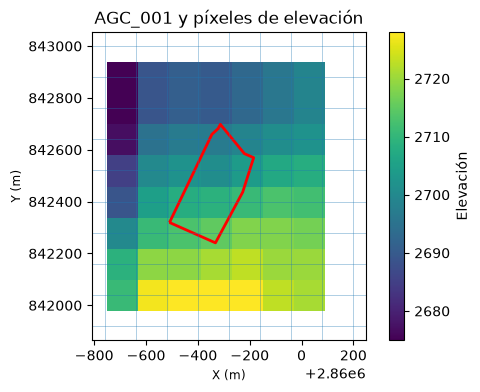

In [10]:
from rasterio.windows import from_bounds

with rasterio.open(elev_path) as src:

    # Límites de AGC_001
    xmin, ymin, xmax, ymax = parcela_repro.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    elevacion = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    elevacion = elevacion.astype(float)
    elevacion[elevacion == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        elevacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_repro.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_001 y píxeles de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(
    im,
    ax=ax,
    label="Elevación"
)

plt.show()

In [11]:
#Considereamos solo ls pixeles en los que la parcela utiliza mas de la mitad del pixel (all_touched=False)
with rasterio.open(elev_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    elev_parcela, transform = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=False)
    
print(elev_parcela.shape)

(1, 5, 3)


In [12]:
from rasterio.mask import mask

#Considereamos solo ls pixeles en los que la parcela utiliza mas de la mitad del pixel (all_touched=False)
with rasterio.open(elev_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    elev_parcela, transform = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=False)
    
print(elev_parcela.shape)

(1, 5, 3)


Obtuvimos la elevación recortado en base a la parcela, es una banda con 5 filas y tres columnas.

In [13]:
# Quitamos la dimensión correspondiente a la banda
elev_valores = elev_parcela[0]

print("Número total de celdas:", elev_valores.size)
print("Número de celdas válidas:", elev_valores.count())
print("Valores de elevación:")
print(elev_valores.compressed())

Número total de celdas: 15
Número de celdas válidas: 6
Valores de elevación:
[2701. 2704. 2709. 2711. 2713. 2715.]


In [14]:
#Considereamos solo ls pixeles que tocan la parcela (all_touched=True)
with rasterio.open(elev_path) as src:
    #Extraemos los pixeles que correponsen a la parcela
    elev_parce, transform_parcela = mask(src, parcela_repro.geometry, crop=True, filled=False, all_touched=True)
    
print(elev_parce.shape)

(1, 5, 3)


In [15]:

elev_vals = elev_parce[0]

print("Número total de celdas:", elev_vals.size)
print("Número de celdas válidas:", elev_vals.count())
print("Valores de elevación:")
print(elev_vals.compressed())

Número total de celdas: 15
Número de celdas válidas: 13
Valores de elevación:
[2697. 2699. 2702. 2701. 2704. 2708. 2709. 2711. 2713. 2715. 2718. 2719.
 2721.]


Vamos a obtener un área ponderada por pixel, es decir, vamos a ver cuanto peso tiene cada pixel en la parcela, si todo el pixel esta dentro del pixel, tendrá un valor del 100%, su peso será de acuerdo a cuanta parte este dentro de la parcela. Utilizamos la mascara en el que están todos los pixeles que están en la parcela.

Utilizamos `box` de `shapely.geometry` para crear un bounding box.
Y para convertir de pixeeles a coordenadas geográficas utilizamos `xy` de `rasterio.transform`.

In [16]:
#Guardamos la geoemetria de la parcela

parcela_geom = parcela_repro.geometry.iloc[0]

pixeles = []

for i in range(elev_vals.shape[0]):
    for j in range(elev_vals.shape[1]):
        
        #Si el pixel esta enmascarado lo ignoramos
        if elev_vals.mask[i, j]:
            continue
        
        #Esquina izquierda superior
        x_iz, y_up = xy(transform_parcela, i, j, offset='ul')
        
        #Esquina inferior derecha
        x_der, y_down = xy(transform_parcela, i, j, offset='lr')
        
        #Bounding box del pixle
        pixel = box(x_iz, y_down, x_der, y_up)        
        
        intersection = pixel.intersection(parcela_geom)
        
        area_intersection = intersection.area
        area_pixel = pixel.area
        proporcion = area_intersection / area_pixel
        
        pixeles.append({
            "fila": i,
            "columna": j,
            "elevacion": elev_vals[i, j],
            "area_pixel_m2": area_pixel,
            "area_interseccion_m2": area_intersection,
            "proporcion": proporcion
        })

In [17]:
df_pixeles = pd.DataFrame(pixeles)

df_pixeles.head()

,fila,columna,elevacion,area_pixel_m2,area_interseccion_m2,proporcion
0,0,1,2697.0,14400.0,2511.258297,0.174393
1,0,2,2699.0,14400.0,128.715312,0.008939
2,1,0,2702.0,14400.0,172.400625,0.011972
3,1,1,2701.0,14400.0,12309.640839,0.854836
4,1,2,2704.0,14400.0,7565.188185,0.525360


In [18]:
print(
    "Área de la parcela:",
    parcela_geom.area,
    "m²"
)

print(
    "Área de intersecciones:",
    df_pixeles["area_interseccion_m2"].sum(),
    "m²"
)


Área de la parcela: 75685.78283383907 m²
Área de intersecciones: 75685.78283386417 m²


In [19]:
elevacion_ponderada = ((df_pixeles['elevacion'] * df_pixeles['area_interseccion_m2']).sum() / df_pixeles['area_interseccion_m2'].sum())

print("Media all_touched=False:", 2708.83)
print("Media all_touched=True:", elev_vals.mean())
print("Media ponderada:", elevacion_ponderada)

Media all_touched=False: 2708.83
Media all_touched=True: 2709.0
Media ponderada: 2708.937487049892


Realizamos una función para replicar con todas las parcelas

In [20]:
def get_area_coverage(parcela, raster_path):
    with rasterio.open(raster_path) as src:
        parcel_raster = parcela.to_crs(src.crs) #Reproyectamos la parcela para que este igual que el raster
        
        geom = [mapping(parcel_raster.geometry.iloc[0])] # Con mapping pasamos a que sea un diccionario GeoJson
        
        #Recortamos el raster en base a la parcel
        values, transform = mask(src, geom, crop=True, filled=False, all_touched=True)
        
        area_total = parcel_raster.geometry.iloc[0].area
        
        area_valida = 0
        
        for i in range(values.shape[1]):
            for j in range(values.shape[2]):
                
                if values.mask[0, i, j]:
                    continue #Ignoramos los NoData
                
                #Obtenemos coordenadas del pixel
                x_left, y_up = xy(transform, i, j, offset='ul')
                x_right, y_down = xy(transform, i, j, offset='lr')
                
                pixel = box(x_left, y_down, x_right, y_up)
                
                intersection = pixel.intersection(parcel_raster.geometry.iloc[0])
                
                area_valida += intersection.area
        
        coverage = area_valida / area_total
        
        return area_total, area_valida, coverage 
        

In [21]:
#Obtenemos para las 197 parcelas

results_cover = []

for _, parcela in parcelas_gdf.iterrows():
    parcela_gdf = gpd.GeoDataFrame([parcela], crs=parcelas_gdf.crs)
    
    area_total, area_valida, cobertura = get_area_coverage(parcela_gdf, elev_path)
    
    results_cover.append({
        'ID_POLIGON': parcela['ID_POLIGON'],
        'area_total_m2': area_total,
        'area_valida_m2': area_valida,
        'cobertura_valida': cobertura,
        'cobertura_valida_pct': cobertura * 100
    })
    
df_cover = pd.DataFrame(results_cover)
    
    

In [22]:
df_cover.head()

,ID_POLIGON,area_total_m2,area_valida_m2,cobertura_valida,cobertura_valida_pct
0,AGC_196,85130.668788,85130.668788,1.000000,100.000000
1,AGC_044,6760.402971,6760.402971,1.000000,100.000000
2,AGC_020,82856.226598,81059.998963,0.978321,97.832115
3,AGC_174,68423.862739,68423.862739,1.000000,100.000000
4,AGC_083,28466.739798,28466.739798,1.000000,100.000000


In [23]:
df_cover.describe()

,area_total_m2,area_valida_m2,cobertura_valida,cobertura_valida_pct
count,197.000000,197.000000,197.000000,197.000000
mean,65597.429526,65444.193570,0.998210,99.820969
std,73875.350018,73844.041198,0.017765,1.776505
min,3492.578960,3492.578960,0.759380,75.938015
25%,22817.430551,22817.430551,1.000000,100.000000
50%,54211.615219,54211.615219,1.000000,100.000000
75%,80305.789972,79867.439975,1.000000,100.000000
max,638659.004590,638659.004590,1.000000,100.000000


In [24]:
print(
    df_cover[
        df_cover["cobertura_valida_pct"] < 99.999
    ][
        ["ID_POLIGON", "cobertura_valida_pct"]
    ]
)


    ID_POLIGON  cobertura_valida_pct
2      AGC_020             97.832115
163    AGC_023             95.899497
175    AGC_170             75.938015
178    AGC_164             95.061206


In [25]:
parcela_170 = parcelas_gdf[
    parcelas_gdf["ID_POLIGON"] == "AGC_170"
].copy()

parcela_170_6372 = parcela_170.to_crs("EPSG:6372")

In [26]:
print(
    "Área parcela:",
    parcela_170_6372.geometry.iloc[0].area,
    "m²"
)

print(
    "Área válida:",
    df_cover.loc[
        df_cover["ID_POLIGON"] == "AGC_170",
        "area_valida_m2"
    ].iloc[0],
    "m²"
)

Área parcela: 80780.08132865428 m²
Área válida: 61342.79030361965 m²


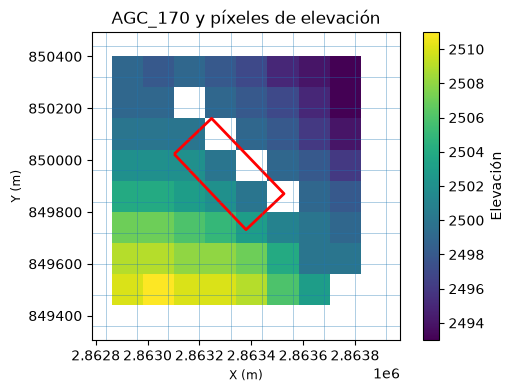

In [28]:

with rasterio.open(elev_path) as src:

    # Límites de AGC_170
    xmin, ymin, xmax, ymax = parcela_170_6372.total_bounds

    # Agregamos un margen de 2 píxeles
    margen = 240

    window = from_bounds(
        xmin - margen,
        ymin - margen,
        xmax + margen,
        ymax + margen,
        src.transform
    )

    # Leer únicamente esa ventana
    elevacion = src.read(1, window=window)

    # Transformación espacial de la ventana
    transform_window = src.window_transform(window)

    # Convertir NoData a NaN
    elevacion = elevacion.astype(float)
    elevacion[elevacion == src.nodata] = np.nan

    # Extensión espacial
    extent = plotting_extent(
        elevacion,
        transform_window
    )

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(
    elevacion,
    extent=extent,
    origin="upper"
)

# Dibujar la parcela
parcela_170_6372.boundary.plot(
    ax=ax,
    linewidth=2,
    color='red'
)

# Dibujar cuadrícula cada 120 m
x_inicio = extent[0]
x_fin = extent[1]

y_inicio = extent[2]
y_fin = extent[3]

for x in np.arange(
    np.floor(x_inicio / 120) * 120,
    x_fin + 120,
    120
):
    ax.axvline(
        x,
        linewidth=0.5,
        alpha=0.5
    )

for y in np.arange(
    np.floor(y_inicio / 120) * 120,
    y_fin + 120,
    120
):
    ax.axhline(
        y,
        linewidth=0.5,
        alpha=0.5
    )

ax.set_title("AGC_170 y píxeles de elevación")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

plt.colorbar(
    im,
    ax=ax,
    label="Elevación"
)

plt.show()

In [29]:
#Función para obtner un dataframe que relacione la parcela con la elevación

def get_elevation(parcela, elev_path):
    with rasterio.open(elev_path) as src:
        
        parcela_raster = parcela.to_crs(src.crs) #Pasamos la parcela a mismo formato del raster
        
        #Obtenemos el poligono de la parcela
        geom_parcela = parcela_raster.geometry.iloc[0]
        geom = [mapping(geom_parcela)]
        
        #Recortamos la parcela alrededor del raster
        parcela_values, transform = mask(src, geom, crop=True, filled=False, all_touched=True)
        
        #Obtenemos el area de la parcela y obtenemos el area que tiene cada pixel dentro de la parcel
        area_total = geom_parcela.area
        area_valida = 0
        average_sum = 0
        
        for i in range(parcela_values.shape[1]):
            for j in range(parcela_values.shape[2]):
                
                if parcela_values.mask[0, i, j]:
                    continue #Ignoramos los No Data
                    
                #Obtemos el valor del raster
                elevacion = parcela_values[0, i, j]
                
                #Valores del pixel
                x_left, y_up = xy(transform, i, j, offset="ul")
                x_right, y_down = xy(transform, i, j, offset="lr")
                
                # Geometría del píxel
                pixel = box(x_left, y_down, x_right, y_up)
                
                #Obtenemos la parte del pixel que pertenece a la parcela
                intersection = pixel.intersection(geom_parcela)
                area_intersection = intersection.area
                area_valida += area_intersection
                
                average_sum += (float(elevacion) * area_intersection)
        
        # Media ponderada
        if area_valida > 0:
            elevacion_media = average_sum / area_valida
        else:
            elevacion_media = np.nan
        
        # Cobertura válida
        cobertura = area_valida / area_total
        
        return {
            "area_total_m2": area_total,
            "area_valida_m2": area_valida,
            "cobertura_elevacion": cobertura,
            "cobertura_elevacion_pct": cobertura * 100,
            "elevacion_media": elevacion_media
        } 